In [1]:
import os
os.chdir("/home/kjk/work") 

In [2]:
from Bio.PDB import PDBParser

PDB_PATH = "data/raw/5X8M.pdb"
parser = PDBParser(QUIET=True)

structure = parser.get_structure("5X8M", PDB_PATH)
model = structure[0]

for chain in model:
    count = 0
    for residue in chain:
        if residue.id[0] == " ":
            count += 1
    print(f"Chain {chain.id} has {count} residues.")

Chain A has 116 residues.
Chain B has 214 residues.
Chain C has 213 residues.


In [3]:
from Bio.PDB import PDBParser

PDB_PATH = "data/raw/5X8M.pdb"

CHAIN_ROLES = {
    "A": "Antigen (PD-L1)",
    "B": "Antibody heavy chain",
    "C": "Antibody light chain",
}


def load_model(pdb_path):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("complex", pdb_path)
    return structure[0]

def get_protein_residues(chain):
    return [res for res in chain if res.id[0] == " "]

model = load_model(PDB_PATH)

for chain in model:
    residues = get_protein_residues(chain)
    role = CHAIN_ROLES.get(chain.id, "Unknown")
    print(f"Chain {chain.id} ({role}) has {len(residues)} residues.")

Chain A (Antigen (PD-L1)) has 116 residues.
Chain B (Antibody heavy chain) has 214 residues.
Chain C (Antibody light chain) has 213 residues.


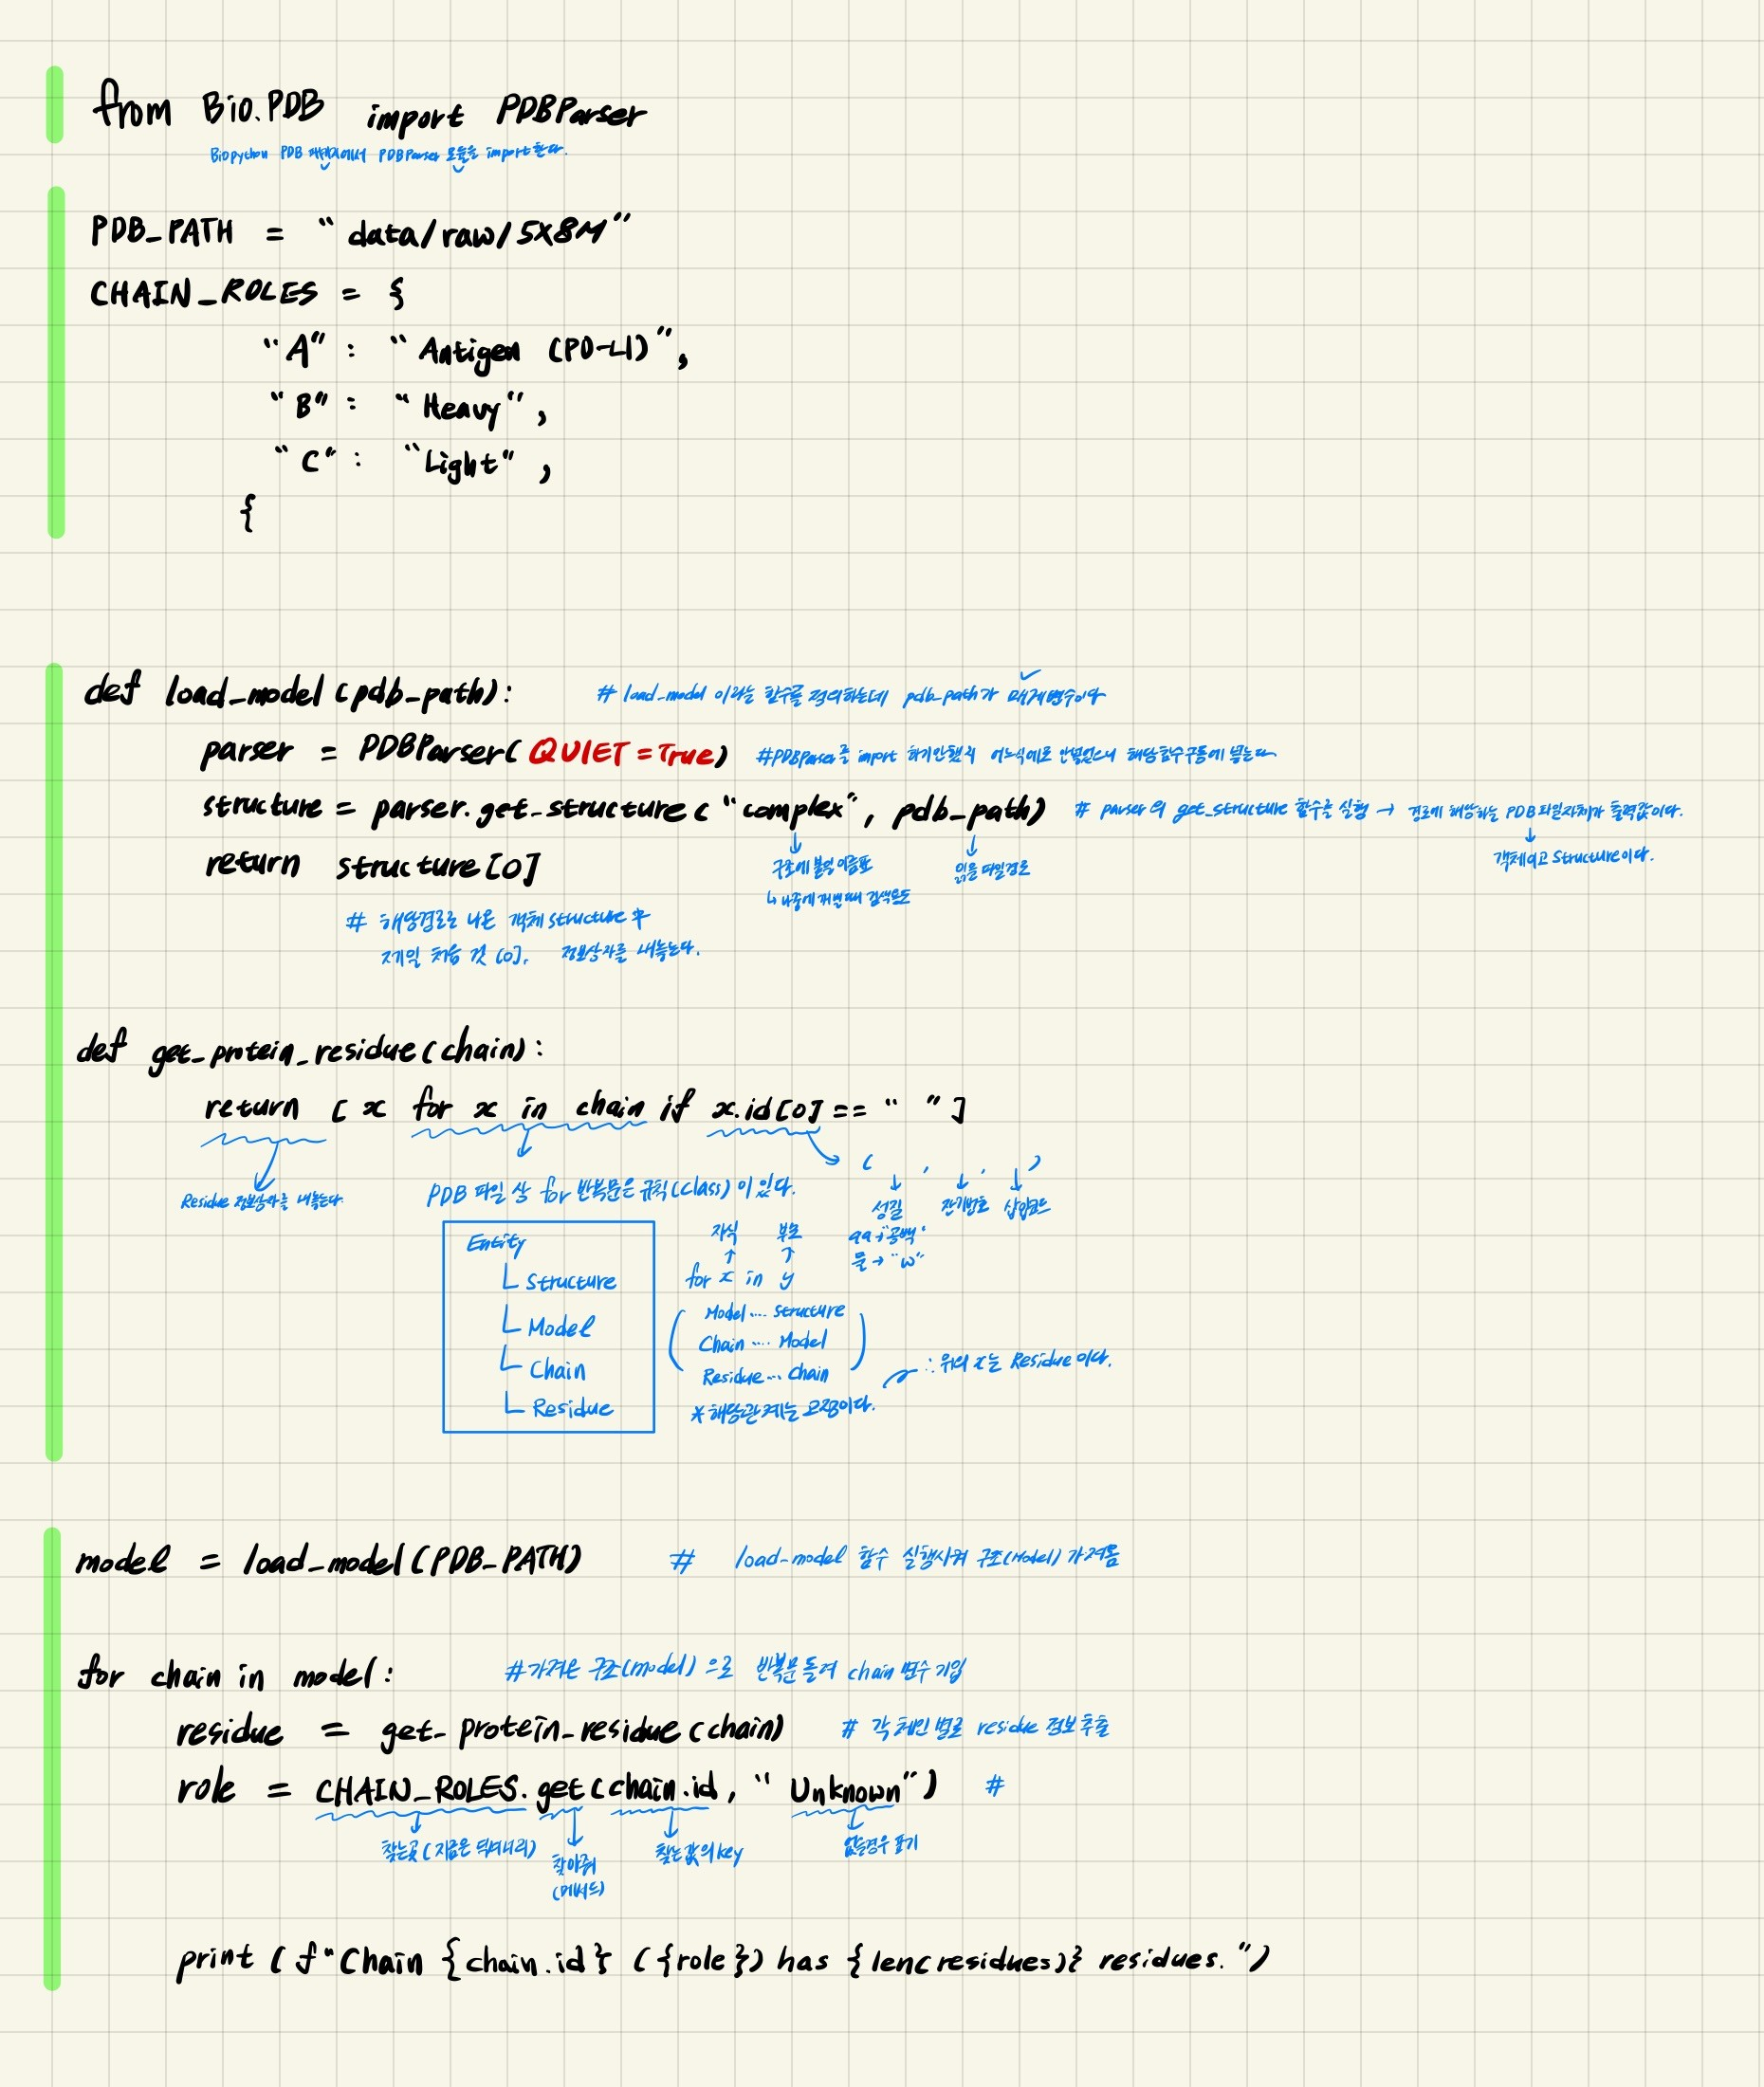

In [4]:
# 과제 A: 첫 잔기와 마지막 잔기
# 각 chain의 첫 번째와 마지막 아미노산의 이름과 번호를 출력

PDB_PATH = "data/raw/5X8M.pdb"

def load_model(pdb_path):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("complex", pdb_path)
    return structure[0]

def load_residues(chain):
    return [res for res in chain if res.id[0] == " "]

model = load_model(PDB_PATH)

for chain in model:
    residues = load_residues(chain)
    print(f"{chain.id} chain first residue: {residues[0].get_resname()}{residues[0].id[1]}")
    print(f"{chain.id} chain last residue: {residues[-1].get_resname()}{residues[-1].id[1]}")

A chain first residue: ALA18
A chain last residue: PRO133
B chain first residue: GLU1
B chain last residue: LYS222
C chain first residue: ILE2
C chain last residue: GLU214


In [5]:
# 과제 B: 물 분자 개수
# 각 chain에 물 분자가 몇 개인지 세서 함께 출력하세요.

PDB_PATH = "data/raw/5X8M.pdb"

def load_model(pdb_path):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("complex", pdb_path)
    return structure[0]

def load_water(chain):
    return [w for w in chain if w.id[0] == "W"]

model = load_model(PDB_PATH)

for chain in model:
    water = load_water(chain)
    print(f"chain {chain.id} water 갯수:{len(water)}")

chain A water 갯수:16
chain B water 갯수:27
chain C water 갯수:30


In [7]:
# 과제 C: 빠진 잔기 찾기 ★ 중요
# 출력을 보면 이상한 점이 있어요. Heavy chain(B)은 번호가 1부터 222까지인데 잔기는 214개뿐이에요. 중간에 **8개가 빠져** 있습니다.
# 번호가 건너뛰는 구간을 찾는 함수 `find_gaps(residues)`를 작성하세요.

PDB_PATH = "data/raw/5X8M.pdb"

CHAIN_ROLES = {
    "A": "Antigen (PD-L1)",
    "B": "Antibody heavy chain",
    "C": "Antibody light chain",
}


def load_model(pdb_path):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("complex", pdb_path)
    return structure[0]

def get_protein_residues(chain):
    return [res for res in chain if res.id[0] == " "]

def find_gaps(residues):
    gaps = []
    prev = None
    for res in residues:
        curr =res.id[1]
        if prev is not None and curr - prev > 1:
            gaps.append((prev, curr))
        prev = curr
    return gaps

models = load_model(PDB_PATH)

for chain in models:
    
    residues = get_protein_residues(chain)
    gap_list = find_gaps(residues)
    print(f"chain id: {chain.id} gap position: {sorted(gap_list)}")


chain id: A gap position: []
chain id: B gap position: [(134, 143)]
chain id: C gap position: []
